In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import  StratifiedKFold
from econml.dml import LinearDML, CausalForestDML
from lightgbm import LGBMClassifier, LGBMRegressor
from sklearn.dummy import DummyClassifier
from econml.dr import ForestDRLearner
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt


train = pd.read_csv("../Data/Processed/train.csv")
test = pd.read_csv("../Data/Processed/test.csv")
print(train.shape, test.shape)

(51200, 13) (12800, 13)


In [2]:
TREATMENT_COL = "segment"
OUTCOME_COL = "conversion"
CONTROL = "No E-Mail"
ID_COL = "Customer ID"

FEATURE_COLS = ["recency", "history", "mens", "womens", "newbie", "history_floor", "zip_code", "channel"]

LGBM_PARAMS = dict(n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=100,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)

cat_ohe = ["zip_code", "channel"]

In [3]:
preprocessor = ColumnTransformer(
    transformers=[
        ("passthrough_cols", "passthrough", ["recency", "mens", "womens", "newbie", "history_floor"]),
        ("history_log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), ["history"]),
        ("cat_ohe", OneHotEncoder(drop=["Rural", "Multichannel"], handle_unknown="ignore", sparse_output=False), cat_ohe),
    ],
    remainder="drop", verbose_feature_names_out=False,
).set_output(transform="pandas")

# DML Pipeline

In [4]:
class DMLPipeline:
    
    def __init__(self, preprocessor, estimator, feature_cols, treatment_col, outcome_col, control):
        self.preprocessor = preprocessor
        self.estimator = estimator
        self.feature_cols = feature_cols
        self.treatment_col = treatment_col
        self.outcome_col = outcome_col
        self.control = control
        
    def fit(self, df):
        X = self.preprocessor.fit_transform(df[self.feature_cols])    
        self.estimator.fit(Y=df[self.outcome_col].values, T=df[self.treatment_col].values, X=X.values)
        self.arms_ = [a for a in sorted(df[self.treatment_col].unique()) if a != self.control]
        self.feature_names_ = list(X.columns)
        return self
    
    def effects(self, df):
        X = self.preprocessor.transform(df[self.feature_cols]).values
        out = {f"ite_{arm.replace(' E-Mail', '').lower()}":
               np.ravel(self.estimator.effect(X, T0=self.control, T1=arm)) for arm in self.arms_}
        return pd.DataFrame(out, index=df.index)
        
    def recommend(self, df):
        eff = self.effects(df)
        best = pd.Series(self.arms_, index=eff.columns).reindex(eff.idxmax(axis=1)).values
        best = np.where(eff.max(axis=1) > 0, best, self.control)
        return eff.assign(best_segment=best)

# Uplift And Qini Curve 

In [5]:
ARMS = {"Mens E-Mail": "ite_mens", "Womens E-Mail": "ite_womens"}
GRID = np.linspace(0.01, 1.0, 100)             # share of customers e-mailed (highest predicted effect first)

def arm_data(arm):
    """Test rows that got either `arm` or the control, as plain arrays."""
    m = test[TREATMENT_COL].isin([CONTROL, arm]).to_numpy()
    y = test.loc[m, OUTCOME_COL].to_numpy(dtype=float)
    tr = (test.loc[m, TREATMENT_COL] == arm).to_numpy(dtype=float)
    return m, y, tr

def curves(y, tr, score):
    """Qini curve (extra conversions per 1,000 customers) and uplift curve (pp among those targeted)."""
    order = np.argsort(-score, kind="stable")
    y, tr = y[order], tr[order]
    cy_t, cy_c = np.cumsum(y * tr), np.cumsum(y * (1 - tr))
    c_t, c_c = np.cumsum(tr), np.cumsum(1 - tr)
    idx = np.clip((GRID * len(y)).astype(int) - 1, 0, len(y) - 1)
    nt, nc = np.maximum(c_t[idx], 1), np.maximum(c_c[idx], 1)
    qini = (cy_t[idx] - cy_c[idx] * nt / nc) / tr.sum() * 1000
    uplift = (cy_t[idx] / nt - cy_c[idx] / nc) * 100
    return qini, uplift

def qini_area(qini):
    """Average gap between the Qini curve and random targeting (extra conversions per 1,000 customers)."""
    x = np.r_[0.0, GRID]
    gap = np.r_[0.0, qini] - np.r_[0.0, qini[-1] * GRID]
    return float(np.sum(np.diff(x) * (gap[1:] + gap[:-1]) / 2))

def curve_report(name, rec_df, n_boot=300, seed=0):
    """Qini and uplift curves (with 90% bootstrap bands) for ONE model, for both e-mail arms."""
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    rows = []
    for i, (arm, col) in enumerate(ARMS.items()):
        m, y, tr = arm_data(arm)
        s, n = rec_df[col].to_numpy()[m], len(y)
        qini, uplift = curves(y, tr, s)
        boots = [curves(y[b], tr[b], s[b]) for b in (rng.integers(0, n, n) for _ in range(n_boot))]
        bq, bu = np.array([b[0] for b in boots]), np.array([b[1] for b in boots])
        areas = np.array([qini_area(q) for q in bq])
        qlo, qhi = np.percentile(bq, [5, 95], axis=0)
        ulo, uhi = np.percentile(bu, [5, 95], axis=0)

        ax = axes[i, 0]
        ax.plot(GRID * 100, qini, label=name)
        ax.fill_between(GRID * 100, qlo, qhi, alpha=0.2)
        ax.plot(GRID * 100, qini[-1] * GRID, "k--", label="random targeting")
        ax.set(title=f"Qini curve: {arm} vs {CONTROL}", xlabel="% of customers e-mailed (highest predicted effect first)",
               ylabel="extra conversions per 1,000 customers")
        ax.legend()

        ax, keep = axes[i, 1], GRID >= 0.05
        ax.plot(GRID[keep] * 100, uplift[keep], label=name)
        ax.fill_between(GRID[keep] * 100, ulo[keep], uhi[keep], alpha=0.2)
        ax.axhline(uplift[-1], color="k", ls="--", label="average effect (everyone)")
        ax.set(title=f"Uplift curve: {arm} vs {CONTROL}", xlabel="% of customers e-mailed (highest predicted effect first)",
               ylabel="observed uplift among those e-mailed (pp)")
        ax.legend()

        k = np.argmin(np.abs(GRID - 0.30))
        rows.append({"model": name, "arm": arm, "Qini area": qini_area(qini),
                     "90% CI low": np.percentile(areas, 5), "90% CI high": np.percentile(areas, 95),
                     "top 30%: extra conv. per 1,000": qini[k], "random targeting": qini[-1] * GRID[k]})
    fig.suptitle(name, fontsize=13)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(rows).round(3)

def compare_curves(models_out, reference=None, n_boot=300, seed=0):
    """All models on the same axes, plus a paired bootstrap of each model's Qini area against a reference model."""
    reference = reference or list(models_out)[0]
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    rows = []
    for i, (arm, col) in enumerate(ARMS.items()):
        m, y, tr = arm_data(arm)
        n = len(y)
        scores = {k: r[col].to_numpy()[m] for k, r in models_out.items()}
        boot_idx = [rng.integers(0, n, n) for _ in range(n_boot)]       # same resamples for every model -> paired
        areas, point = {}, {}
        for k, s in scores.items():
            qini, uplift = curves(y, tr, s)
            point[k] = qini_area(qini)
            areas[k] = np.array([qini_area(curves(y[b], tr[b], s[b])[0]) for b in boot_idx])
            axes[i, 0].plot(GRID * 100, qini, label=k)
            keep = GRID >= 0.05
            axes[i, 1].plot(GRID[keep] * 100, uplift[keep], label=k)
        axes[i, 0].plot(GRID * 100, qini[-1] * GRID, "k--", label="random targeting")
        axes[i, 0].set(title=f"Qini curves: {arm} vs {CONTROL}", xlabel="% of customers e-mailed",
                       ylabel="extra conversions per 1,000 customers")
        axes[i, 1].axhline(uplift[-1], color="k", ls="--", label="average effect (everyone)")
        axes[i, 1].set(title=f"Uplift curves: {arm} vs {CONTROL}", xlabel="% of customers e-mailed",
                       ylabel="observed uplift among those e-mailed (pp)")
        axes[i, 0].legend(fontsize=8); axes[i, 1].legend(fontsize=8)
        for k in scores:
            d = areas[k] - areas[reference]
            rows.append({"arm": arm, "model": k, "Qini area": point[k],
                         "90% CI low": np.percentile(areas[k], 5), "90% CI high": np.percentile(areas[k], 95),
                         f"diff vs {reference}": point[k] - point[reference],
                         "diff CI low": np.percentile(d, 5) if k != reference else np.nan,
                         "diff CI high": np.percentile(d, 95) if k != reference else np.nan})
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(rows).round(3)

## LGBM DML Model

In [6]:
dml=LinearDML(
    model_t=LGBMClassifier(**LGBM_PARAMS),
    model_y=LGBMClassifier(**LGBM_PARAMS),
    discrete_outcome=True,
    discrete_treatment=True,
    cv=5,
    random_state=42
)

dml_pipe=DMLPipeline(preprocessor,dml,FEATURE_COLS,TREATMENT_COL,OUTCOME_COL,CONTROL)

dml_pipe.fit(train)

print("fitted. e-mail arms compared with", CONTROL, "->", dml_pipe.arms_)
print("features seen by the model:", dml_pipe.feature_names_)

fitted. e-mail arms compared with No E-Mail -> ['Mens E-Mail', 'Womens E-Mail']
features seen by the model: ['recency', 'mens', 'womens', 'newbie', 'history_floor', 'history', 'zip_code_Suburban', 'zip_code_Urban', 'channel_Phone', 'channel_Web']


In [7]:
rec = dml_pipe.recommend(test)
rec.insert(0, ID_COL, test[ID_COL].values)
display(rec.head())

print("average estimated effect on the test set (percentage points):")
print((rec[["ite_mens", "ite_womens"]].mean() * 100).round(3).to_string())
print("\nspread across customers (std, pp):")
print((rec[["ite_mens", "ite_womens"]].std() * 100).round(3).to_string())
print("\nbest option per customer:")
print(rec["best_segment"].value_counts().to_string())

,Customer ID,ite_mens,ite_womens,best_segment
0,C-43252,0.007159,0.000417,Mens E-Mail
1,C-7410,0.004933,0.007095,Womens E-Mail
2,C-6444,0.008296,0.005739,Mens E-Mail
3,C-29292,0.005400,-0.000919,Mens E-Mail
4,C-9606,0.008020,0.003897,Mens E-Mail


average estimated effect on the test set (percentage points):
ite_mens      0.677
ite_womens    0.316

spread across customers (std, pp):
ite_mens      0.341
ite_womens    0.363

best option per customer:
best_segment
Mens E-Mail      10319
Womens E-Mail     2240
No E-Mail          241


In [8]:
def uplift_by_bucket(test_df, ite, arm, n_buckets=5):
    d = test_df[[TREATMENT_COL, OUTCOME_COL]].copy()
    d["ite"] = np.asarray(ite)
    d = d[d[TREATMENT_COL].isin([CONTROL, arm])].copy()
    d["bucket"] = pd.qcut(d["ite"], n_buckets, labels=[f"B{i}" for i in range(1, n_buckets + 1)])  
    rows = []
    for b, g in d.groupby("bucket", observed=True):
        treated, control = g[g[TREATMENT_COL] == arm][OUTCOME_COL], g[g[TREATMENT_COL] == CONTROL][OUTCOME_COL]
        rows.append({"bucket": b, "customers": len(g), "predicted uplift (pp)": g["ite"].mean() * 100,
                     "treated conv. (%)": treated.mean() * 100, "control conv. (%)": control.mean() * 100,
                     "observed uplift (pp)": (treated.mean() - control.mean()) * 100})
    return pd.DataFrame(rows).round(3)

for arm, col in [("Mens E-Mail", "ite_mens"), ("Womens E-Mail", "ite_womens")]:
    print(f"\n{arm} vs {CONTROL}")
    print(uplift_by_bucket(test, rec[col], arm).to_string(index=False))


Mens E-Mail vs No E-Mail
bucket  customers  predicted uplift (pp)  treated conv. (%)  control conv. (%)  observed uplift (pp)
    B1       1705                  0.189              1.575              0.490                 1.085
    B2       1704                  0.568              0.700              0.472                 0.228
    B3       1704                  0.699              0.713              0.928                -0.215
    B4       1704                  0.813              1.218              0.340                 0.878
    B5       1705                  1.135              1.995              0.586                 1.409

Womens E-Mail vs No E-Mail
bucket  customers  predicted uplift (pp)  treated conv. (%)  control conv. (%)  observed uplift (pp)
    B1       1708                 -0.195              0.336              0.982                -0.646
    B2       1708                  0.120              1.453              0.567                 0.886
    B3       1707                  0.

In [ ]:
p_convert_pipe=Pipeline([
    ('preprocess', clone(preprocessor)),
    ('model',LGBMClassifier(**LGBM_PARAMS))
])

p_convert_pipe.fit(train[FEATURE_COLS],train[OUTCOME_COL])

rec["p_convert"]=p_convert_pipe.predict_proba(test[FEATURE_COLS])[:,1]
print("test AUC of p_convert:", round(roc_auc_score(test[OUTCOME_COL], rec["p_convert"]), 3), "(modest signal is expected: only 0.9% convert)")

scored_test = rec[[ID_COL, "p_convert", "ite_mens", "ite_womens", "best_segment"]]
scored_test.to_csv("../Data/Processed/scored_test.csv", index=False)
scored_test.head()

test AUC of p_convert: 0.604 (modest signal is expected: only 0.9% convert)


,Customer ID,p_convert,ite_mens,ite_womens,best_segment
0,C-43252,0.011296,0.007159,0.000417,Mens E-Mail
1,C-7410,0.006699,0.004933,0.007095,Womens E-Mail
2,C-6444,0.006844,0.008296,0.005739,Mens E-Mail
3,C-29292,0.005102,0.005400,-0.000919,Mens E-Mail
4,C-9606,0.016517,0.008020,0.003897,Mens E-Mail


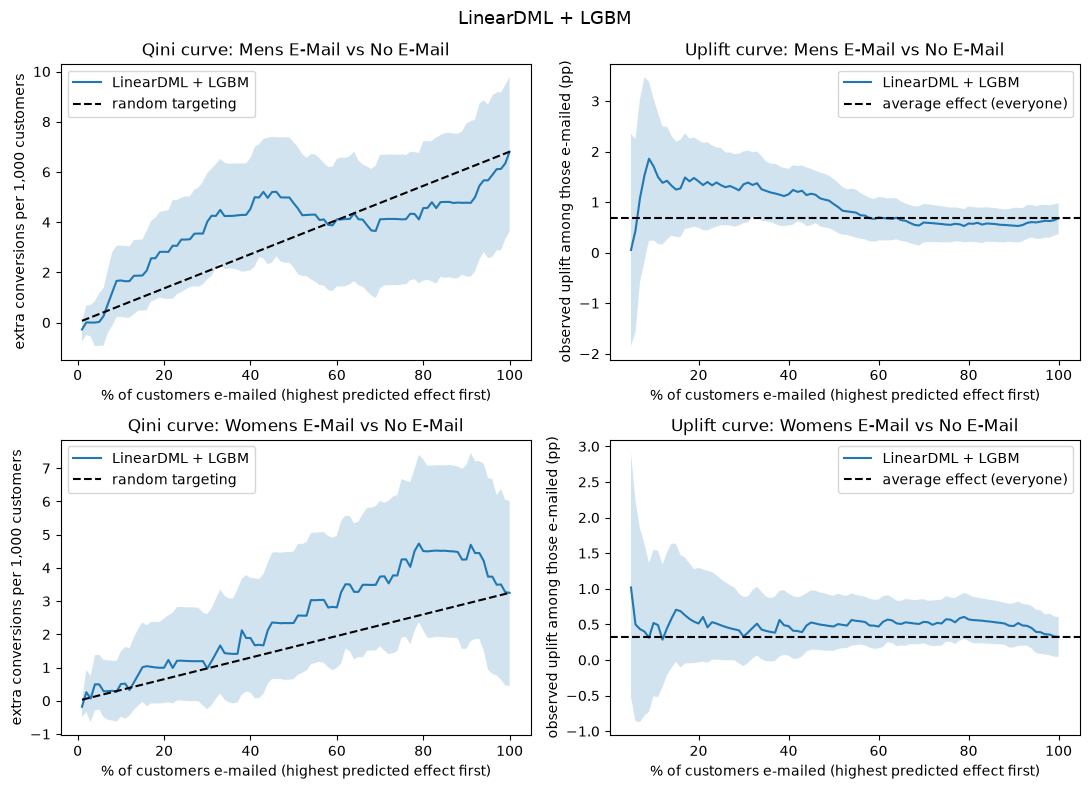

,model,arm,Qini area,90% CI low,90% CI high,"top 30%: extra conv. per 1,000",random targeting
0,LinearDML + LGBM,Mens E-Mail,0.394,-0.720,1.468,4.016,2.042
1,LinearDML + LGBM,Womens E-Mail,0.828,0.035,1.674,0.972,0.975


In [10]:
curve_report("LinearDML + LGBM", rec)

## Random Forest DML Model

In [11]:
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=100, max_features=0.5,
                 n_jobs=-1, random_state=42)

In [12]:
dml_rf = LinearDML(
    model_t=RandomForestClassifier(**RF_PARAMS),
    model_y=RandomForestClassifier(**RF_PARAMS),
    discrete_outcome=True,
    discrete_treatment=True,
    cv=5,
    random_state=42
)

dml_rf_pipe = DMLPipeline(clone(preprocessor), dml_rf, FEATURE_COLS, TREATMENT_COL, OUTCOME_COL, CONTROL)
dml_rf_pipe.fit(train)

print("fitted. e-mail arms compared with", CONTROL, "->", dml_rf_pipe.arms_)
print("features seen by the model:", dml_rf_pipe.feature_names_)

fitted. e-mail arms compared with No E-Mail -> ['Mens E-Mail', 'Womens E-Mail']
features seen by the model: ['recency', 'mens', 'womens', 'newbie', 'history_floor', 'history', 'zip_code_Suburban', 'zip_code_Urban', 'channel_Phone', 'channel_Web']


In [13]:
rec_rf = dml_rf_pipe.recommend(test)
rec_rf.insert(0, ID_COL, test[ID_COL].values)
display(rec_rf.head())

print("average estimated effect on the test set (percentage points):")
print((rec_rf[["ite_mens", "ite_womens"]].mean() * 100).round(3).to_string())
print("\nspread across customers (std, pp):")
print((rec_rf[["ite_mens", "ite_womens"]].std() * 100).round(3).to_string())
print("\nbest option per customer:")
print(rec_rf["best_segment"].value_counts().to_string())

,Customer ID,ite_mens,ite_womens,best_segment
0,C-43252,0.007249,0.000451,Mens E-Mail
1,C-7410,0.004408,0.006788,Womens E-Mail
2,C-6444,0.007849,0.005532,Mens E-Mail
3,C-29292,0.005295,-0.000796,Mens E-Mail
4,C-9606,0.007924,0.003880,Mens E-Mail


average estimated effect on the test set (percentage points):
ite_mens      0.677
ite_womens    0.313

spread across customers (std, pp):
ite_mens      0.344
ite_womens    0.355

best option per customer:
best_segment
Mens E-Mail      10277
Womens E-Mail     2323
No E-Mail          200


In [14]:
for arm, col in [("Mens E-Mail", "ite_mens"), ("Womens E-Mail", "ite_womens")]:
    print(f"\n{arm} vs {CONTROL}")
    print(uplift_by_bucket(test, rec_rf[col], arm).to_string(index=False))


Mens E-Mail vs No E-Mail
bucket  customers  predicted uplift (pp)  treated conv. (%)  control conv. (%)  observed uplift (pp)
    B1       1705                  0.196              1.697              0.365                 1.331
    B2       1704                  0.559              0.581              0.593                -0.012
    B3       1704                  0.693              0.237              0.813                -0.576
    B4       1704                  0.805              1.707              0.452                 1.255
    B5       1705                  1.149              1.993              0.587                 1.406

Womens E-Mail vs No E-Mail
bucket  customers  predicted uplift (pp)  treated conv. (%)  control conv. (%)  observed uplift (pp)
    B1       1708                 -0.185              0.337              1.102                -0.765
    B2       1708                  0.121              1.327              0.455                 0.872
    B3       1707                  0.

In [15]:
p_convert_pipe_rf = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", RandomForestClassifier(**RF_PARAMS))
])

p_convert_pipe_rf.fit(train[FEATURE_COLS], train[OUTCOME_COL])

rec_rf["p_convert"] = p_convert_pipe_rf.predict_proba(test[FEATURE_COLS])[:, 1]
print("test AUC of p_convert (RF):", round(roc_auc_score(test[OUTCOME_COL], rec_rf["p_convert"]), 3))

scored_test_rf = rec_rf[[ID_COL, "p_convert", "ite_mens", "ite_womens", "best_segment"]]
scored_test_rf.to_csv("../Data/Processed/scored_test_rf.csv", index=False)   # separate file: does not overwrite the LGBM output
scored_test_rf.head()

test AUC of p_convert (RF): 0.616


,Customer ID,p_convert,ite_mens,ite_womens,best_segment
0,C-43252,0.011657,0.007249,0.000451,Mens E-Mail
1,C-7410,0.009607,0.004408,0.006788,Womens E-Mail
2,C-6444,0.007253,0.007849,0.005532,Mens E-Mail
3,C-29292,0.007333,0.005295,-0.000796,Mens E-Mail
4,C-9606,0.019644,0.007924,0.003880,Mens E-Mail


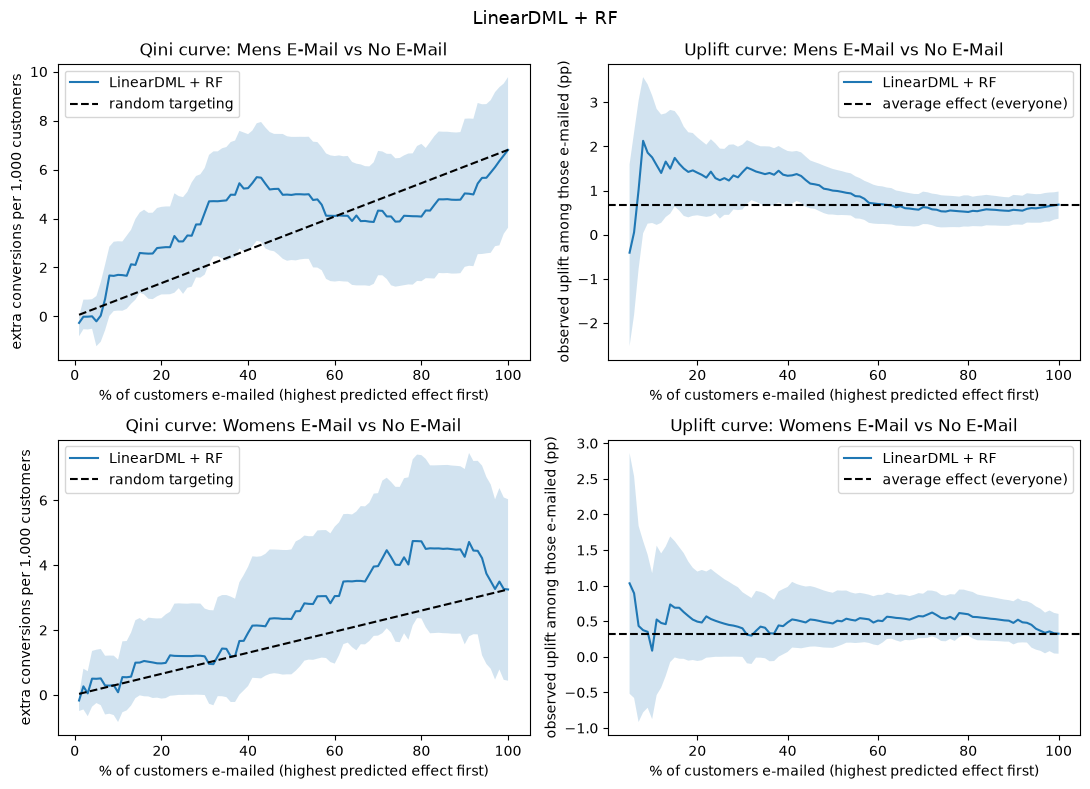

,model,arm,Qini area,90% CI low,90% CI high,"top 30%: extra conv. per 1,000",random targeting
0,LinearDML + RF,Mens E-Mail,0.534,-0.635,1.616,4.235,2.042
1,LinearDML + RF,Womens E-Mail,0.860,0.110,1.743,1.189,0.975


In [16]:
curve_report("LinearDML + RF", rec_rf)

## CausalForest DML Model

In [17]:
dml_cf = CausalForestDML(
    model_t=LGBMClassifier(**LGBM_PARAMS),
    model_y=LGBMClassifier(**LGBM_PARAMS),
    discrete_outcome=True, discrete_treatment=True, cv=5,
    n_estimators=500, min_samples_leaf=200, honest=True, n_jobs=-1, random_state=42,
)
cf_pipe = DMLPipeline(clone(preprocessor), dml_cf, FEATURE_COLS, TREATMENT_COL, OUTCOME_COL, CONTROL)
cf_pipe.fit(train)

print("fitted. e-mail arms compared with", CONTROL, "->", cf_pipe.arms_)
print("features seen by the model:", cf_pipe.feature_names_)

fitted. e-mail arms compared with No E-Mail -> ['Mens E-Mail', 'Womens E-Mail']
features seen by the model: ['recency', 'mens', 'womens', 'newbie', 'history_floor', 'history', 'zip_code_Suburban', 'zip_code_Urban', 'channel_Phone', 'channel_Web']


In [19]:
rec_cf = cf_pipe.recommend(test)
rec_cf.insert(0, ID_COL, test[ID_COL].values)
display(rec_cf.head())

print("average estimated effect on the test set (percentage points):")
print((rec_cf[["ite_mens", "ite_womens"]].mean() * 100).round(3).to_string())
print("\nspread across customers (std, pp):")
print((rec_cf[["ite_mens", "ite_womens"]].std() * 100).round(3).to_string())
print("\nbest option per customer:")
print(rec_cf["best_segment"].value_counts().to_string())

,Customer ID,ite_mens,ite_womens,best_segment
0,C-43252,0.004315,-0.003723,Mens E-Mail
1,C-7410,0.005986,0.006155,Womens E-Mail
2,C-6444,0.005861,0.007045,Womens E-Mail
3,C-29292,0.003141,-0.000732,Mens E-Mail
4,C-9606,0.014929,0.011361,Mens E-Mail


average estimated effect on the test set (percentage points):
ite_mens      0.670
ite_womens    0.314

spread across customers (std, pp):
ite_mens      0.279
ite_womens    0.379

best option per customer:
best_segment
Mens E-Mail      10284
Womens E-Mail     2512
No E-Mail            4


In [20]:
for arm, col in [("Mens E-Mail", "ite_mens"), ("Womens E-Mail", "ite_womens")]:
    print(f"\n{arm} vs {CONTROL}")
    print(uplift_by_bucket(test, rec_cf[col], arm).to_string(index=False))


Mens E-Mail vs No E-Mail
bucket  customers  predicted uplift (pp)  treated conv. (%)  control conv. (%)  observed uplift (pp)
    B1       1705                  0.313              0.586              0.587                -0.001
    B2       1704                  0.516              0.597              0.231                 0.366
    B3       1705                  0.651              1.356              0.610                 0.746
    B4       1703                  0.795              1.775              0.583                 1.192
    B5       1705                  1.093              1.905              0.809                 1.096

Womens E-Mail vs No E-Mail
bucket  customers  predicted uplift (pp)  treated conv. (%)  control conv. (%)  observed uplift (pp)
    B1       1708                 -0.201              0.821              0.585                 0.236
    B2       1708                  0.110              1.039              0.713                 0.327
    B3       1707                  0.

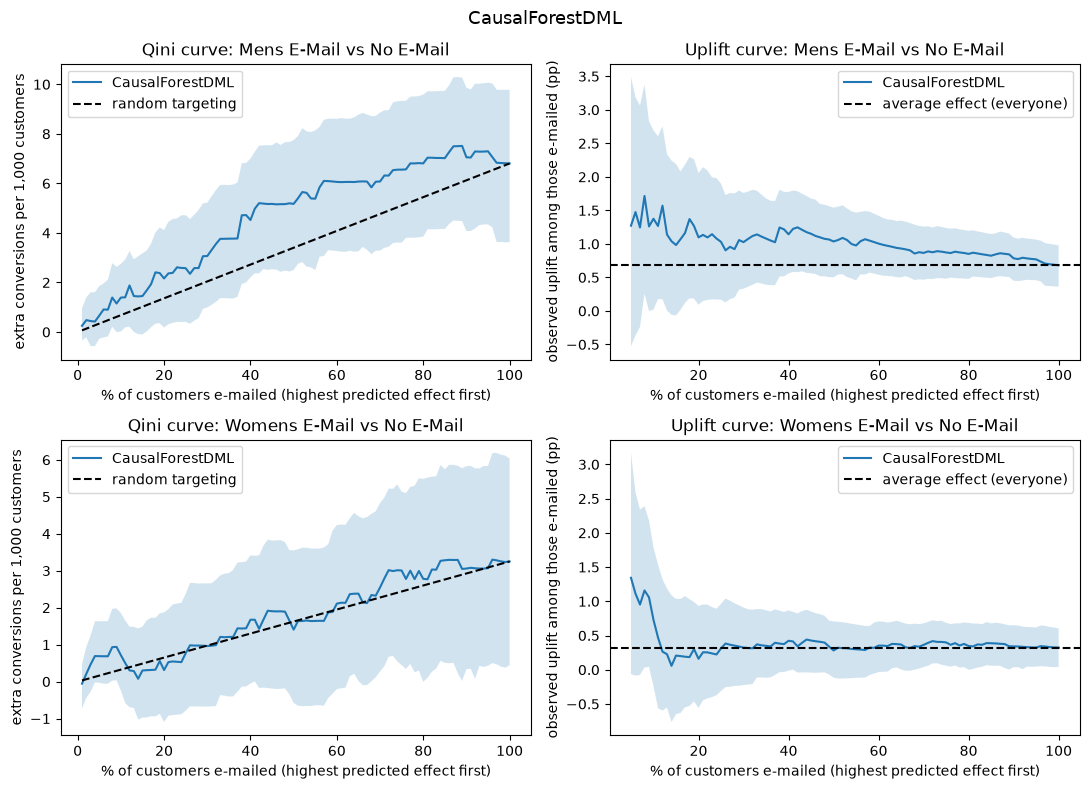

,model,arm,Qini area,90% CI low,90% CI high,"top 30%: extra conv. per 1,000",random targeting
0,CausalForestDML,Mens E-Mail,1.265,0.263,2.328,3.067,2.042
1,CausalForestDML,Womens E-Mail,0.154,-0.727,1.013,0.963,0.975


In [21]:
curve_report("CausalForestDML", rec_cf)

# ForestDRLearner Model

In [22]:
dr = ForestDRLearner(
    model_propensity=DummyClassifier(strategy="prior"),   # fine only because assignment was randomised
    model_regression=LGBMRegressor(**LGBM_PARAMS),
    cv=5, n_estimators=500, min_samples_leaf=200, n_jobs=-1, random_state=42,
)
dr_pipe = DMLPipeline(clone(preprocessor), dr, FEATURE_COLS, TREATMENT_COL, OUTCOME_COL, CONTROL)
dr_pipe.fit(train)


print("fitted. e-mail arms compared with", CONTROL, "->", dr_pipe.arms_)
print("features seen by the model:", dr_pipe.feature_names_)

fitted. e-mail arms compared with No E-Mail -> ['Mens E-Mail', 'Womens E-Mail']
features seen by the model: ['recency', 'mens', 'womens', 'newbie', 'history_floor', 'history', 'zip_code_Suburban', 'zip_code_Urban', 'channel_Phone', 'channel_Web']


In [23]:
rec_dr = dr_pipe.recommend(test)
rec_dr.insert(0, ID_COL, test[ID_COL].values)
display(rec_dr.head())

print("average estimated effect on the test set (percentage points):")
print((rec_dr[["ite_mens", "ite_womens"]].mean() * 100).round(3).to_string())
print("\nspread across customers (std, pp):")
print((rec_dr[["ite_mens", "ite_womens"]].std() * 100).round(3).to_string())
print("\nbest option per customer:")
print(rec_dr["best_segment"].value_counts().to_string())

,Customer ID,ite_mens,ite_womens,best_segment
0,C-43252,0.003503,-0.004238,Mens E-Mail
1,C-7410,0.006661,0.007013,Womens E-Mail
2,C-6444,0.005482,0.005974,Womens E-Mail
3,C-29292,0.003731,-0.000484,Mens E-Mail
4,C-9606,0.013276,0.010018,Mens E-Mail


average estimated effect on the test set (percentage points):
ite_mens      0.668
ite_womens    0.305

spread across customers (std, pp):
ite_mens      0.277
ite_womens    0.372

best option per customer:
best_segment
Mens E-Mail      10294
Womens E-Mail     2506


In [24]:
for arm, col in [("Mens E-Mail", "ite_mens"), ("Womens E-Mail", "ite_womens")]:
    print(f"\n{arm} vs {CONTROL}")
    print(uplift_by_bucket(test, rec_dr[col], arm).to_string(index=False))


Mens E-Mail vs No E-Mail
bucket  customers  predicted uplift (pp)  treated conv. (%)  control conv. (%)  observed uplift (pp)
    B1       1705                  0.310              0.481              0.572                -0.091
    B2       1704                  0.516              1.168              0.472                 0.697
    B3       1704                  0.654              1.278              0.356                 0.922
    B4       1704                  0.800              1.515              0.827                 0.688
    B5       1705                  1.083              1.754              0.588                 1.166

Womens E-Mail vs No E-Mail
bucket  customers  predicted uplift (pp)  treated conv. (%)  control conv. (%)  observed uplift (pp)
    B1       1708                 -0.194              0.922              0.952                -0.031
    B2       1708                  0.091              0.948              0.347                 0.601
    B3       1711                  0.

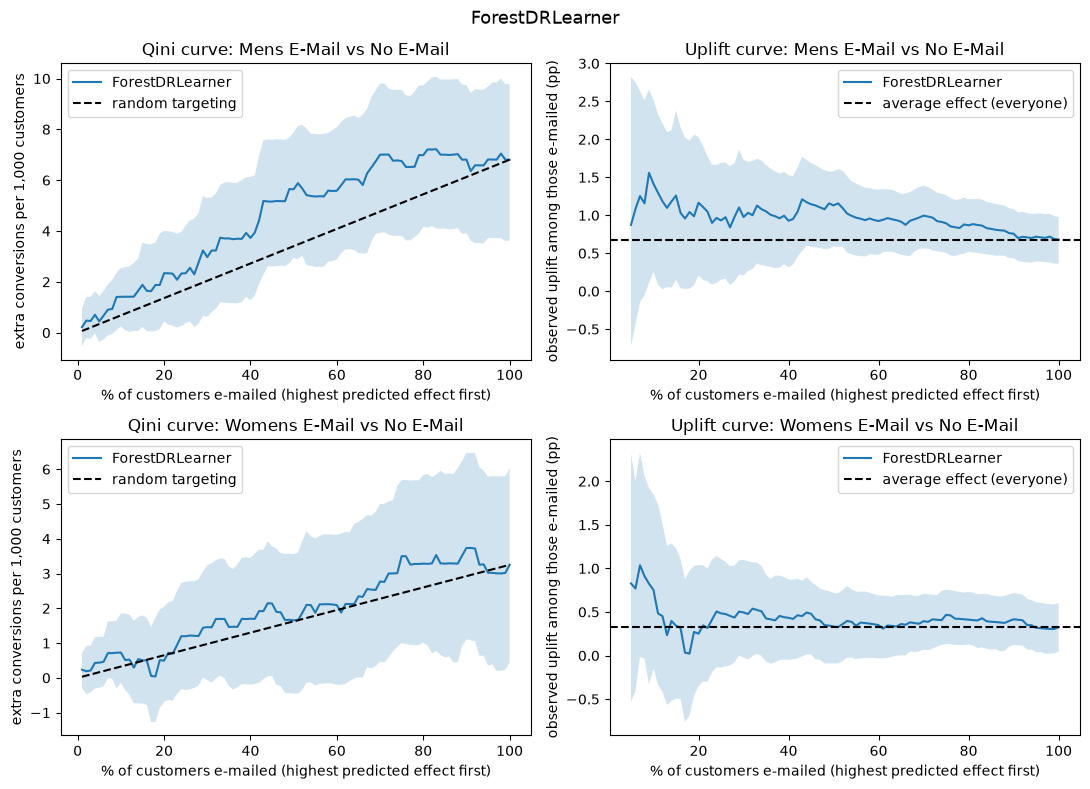

,model,arm,Qini area,90% CI low,90% CI high,"top 30%: extra conv. per 1,000",random targeting
0,ForestDRLearner,Mens E-Mail,1.161,0.159,2.161,2.973,2.042
1,ForestDRLearner,Womens E-Mail,0.320,-0.541,1.291,1.459,0.975


In [25]:
curve_report("ForestDRLearner", rec_dr)

## confidence intervals and feature importances

In [26]:
X_test = cf_pipe.preprocessor.transform(test[FEATURE_COLS]).values
lo, hi = dml_cf.effect_interval(X_test, T0=CONTROL, T1="Mens E-Mail", alpha=0.1)
print("share of customers with 90% CI above 0 (Mens):", round(float((np.ravel(lo) > 0).mean()), 3))
print(pd.Series(dml_cf.feature_importances_, index=cf_pipe.feature_names_).sort_values(ascending=False).round(3))

share of customers with 90% CI above 0 (Mens): 0.708
history              0.622
recency              0.160
mens                 0.044
zip_code_Suburban    0.036
newbie               0.031
womens               0.031
zip_code_Urban       0.029
channel_Phone        0.023
channel_Web          0.021
history_floor        0.001
dtype: float64


# Comparing all models

In [27]:
Xtr = clone(preprocessor).fit_transform(train[FEATURE_COLS]).to_numpy()
y = train[OUTCOME_COL].to_numpy()
t = train[TREATMENT_COL].to_numpy()
classes = np.unique(t)
t_idx = np.searchsorted(classes, t)
t_onehot = np.eye(len(classes))[t_idx]

# same fold design as EconML's cross-fitting: 5 shuffled folds, stratified on conversion x e-mail group
strata = np.char.add(y.astype(str), t.astype(str))
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(Xtr, strata))

def oof(model, features, target, proba):
    out = None
    for tr, va in folds:
        m = clone(model).fit(features[tr], target[tr])
        p = m.predict_proba(features[va]) if proba else m.predict(features[va])
        if out is None:
            out = np.zeros((len(target),) + p.shape[1:])
        out[va] = p
    return out

eps = 1e-15
def logloss_rows(p1, y):
    p1 = np.clip(p1, eps, 1 - eps)
    return -(y * np.log(p1) + (1 - y) * np.log(1 - p1))

def verdict(diff, se):
    return "better than baseline" if diff + 2 * se < 0 else "worse than baseline" if diff - 2 * se > 0 else "no clear difference"

def row(setup, nuisance, metric, loss_model, loss_base, auc=np.nan):
    d = loss_model - loss_base                       # paired, per customer; negative = model beats the baseline
    diff, se = d.mean(), d.std() / np.sqrt(len(d))
    return {"setup": setup, "nuisance": nuisance, "metric": metric, "model": loss_model.mean(), "baseline": loss_base.mean(),
            "diff": diff, "diff SE": se, "AUC": auc, "verdict": verdict(diff, se)}

# the nuisance learners each model really uses (CausalForestDML shares LinearDML+LGBM's; ForestDRLearner differs)
setups = {
    "LinearDML + LGBM (and CausalForestDML)": dict(y=LGBMClassifier(**LGBM_PARAMS), t=LGBMClassifier(**LGBM_PARAMS)),
    "LinearDML + RF": dict(y=RandomForestClassifier(**RF_PARAMS), t=RandomForestClassifier(**RF_PARAMS)),
}
rows = []
base_y = logloss_rows(np.full(len(y), y.mean()), y)                       # constant conversion probability
share = np.array([(t == c).mean() for c in classes])
base_t = -np.log(share[t_idx])                                            # constant propensity = actual group shares
for name, s in setups.items():
    p = oof(s["y"], Xtr, y, proba=True)[:, 1]
    rows.append(row(name, "outcome model", "log-loss", logloss_rows(p, y), base_y, roc_auc_score(y, p)))
    pt = oof(s["t"], Xtr, t, proba=True)
    rows.append(row(name, "treatment model", "log-loss", -np.log(np.clip(pt[np.arange(len(t)), t_idx], eps, 1)), base_t))

# ForestDRLearner: constant propensity (nothing to evaluate) + a regression of conversion on features AND e-mail group
Xt = np.column_stack([Xtr, t_onehot])
pred = oof(LGBMRegressor(**LGBM_PARAMS), Xt, y, proba=False)
arm_mean = np.array([y[t_idx == k].mean() for k in range(len(classes))])[t_idx]
rows.append(row("ForestDRLearner", "outcome regression (X + e-mail group)", "squared error", (y - pred) ** 2, (y - arm_mean) ** 2))

nuisance_table = pd.DataFrame(rows)
nuisance_table.round(6)

,setup,nuisance,metric,model,baseline,diff,diff SE,AUC,verdict
0,LinearDML + LGBM (and CausalForestDML),outcome model,log-loss,0.052528,0.051556,0.000972,0.000321,0.564453,worse than baseline
1,LinearDML + LGBM (and CausalForestDML),treatment model,log-loss,1.101326,1.098611,0.002716,0.000373,NaN,worse than baseline
2,LinearDML + RF,outcome model,log-loss,0.052106,0.051556,0.000550,0.000297,0.567072,no clear difference
3,LinearDML + RF,treatment model,log-loss,1.100322,1.098611,0.001711,0.000299,NaN,worse than baseline
4,ForestDRLearner,outcome regression (X + e-mail group),squared error,0.008979,0.008953,0.000026,0.000008,NaN,worse than baseline


## Qini and Uplift

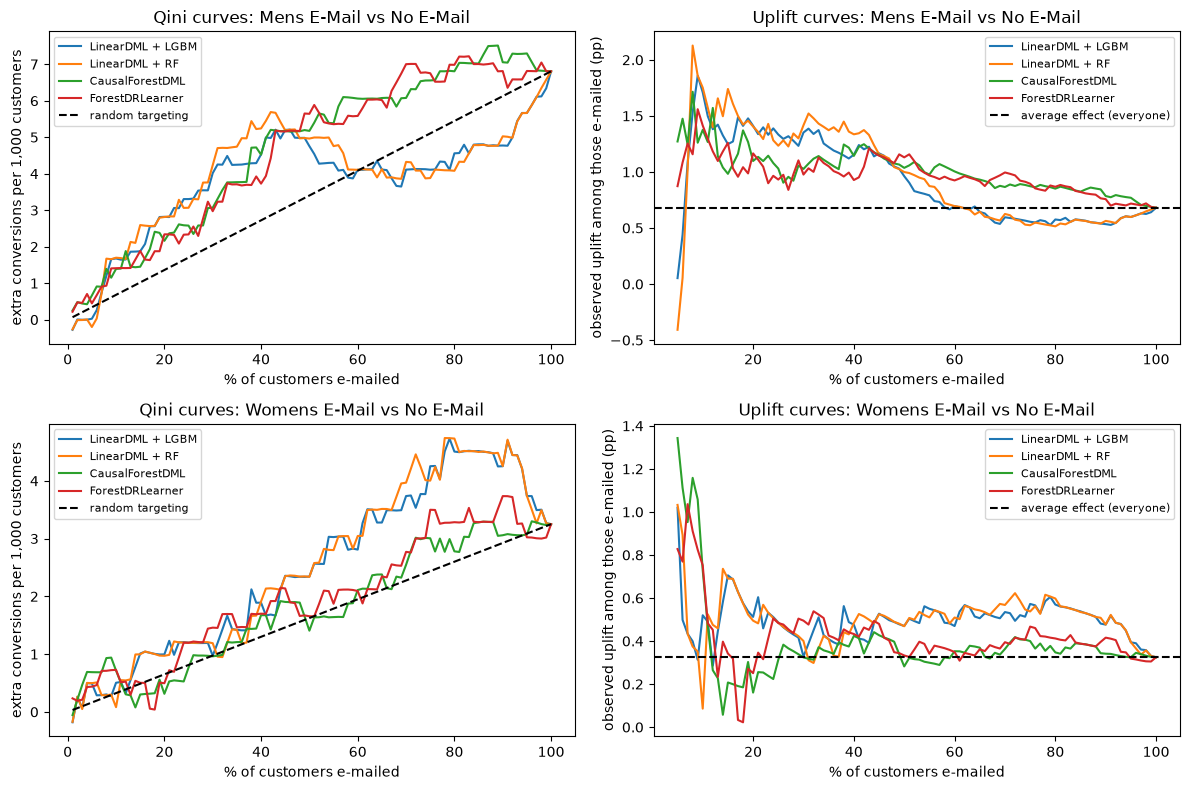

,arm,model,Qini area,90% CI low,90% CI high,diff vs LinearDML + LGBM,diff CI low,diff CI high
0,Mens E-Mail,LinearDML + LGBM,0.394,-0.720,1.468,0.000,NaN,NaN
1,Mens E-Mail,LinearDML + RF,0.534,-0.635,1.616,0.140,-0.051,0.302
2,Mens E-Mail,CausalForestDML,1.265,0.263,2.328,0.871,-0.233,2.090
3,Mens E-Mail,ForestDRLearner,1.161,0.159,2.161,0.767,-0.261,1.850
4,Womens E-Mail,LinearDML + LGBM,0.828,0.035,1.674,0.000,NaN,NaN
5,Womens E-Mail,LinearDML + RF,0.860,0.110,1.743,0.032,-0.014,0.071
6,Womens E-Mail,CausalForestDML,0.154,-0.727,1.013,-0.674,-1.678,0.244
7,Womens E-Mail,ForestDRLearner,0.320,-0.541,1.291,-0.508,-1.560,0.405


In [28]:
models_out = {"LinearDML + LGBM": rec, "LinearDML + RF": rec_rf,
              "CausalForestDML": rec_cf, "ForestDRLearner": rec_dr}
compare_curves(models_out, reference="LinearDML + LGBM")

In [29]:
full = pd.concat([train, test], ignore_index=True)
full_strata = np.char.add(full[OUTCOME_COL].astype(str), full[TREATMENT_COL].astype(str))

model_factories = {
    "LinearDML + LGBM": lambda: DMLPipeline(clone(preprocessor), LinearDML(
        model_t=LGBMClassifier(**LGBM_PARAMS), model_y=LGBMClassifier(**LGBM_PARAMS),
        discrete_outcome=True, discrete_treatment=True, cv=5, random_state=42),
        FEATURE_COLS, TREATMENT_COL, OUTCOME_COL, CONTROL),
    "LinearDML + RF": lambda: DMLPipeline(clone(preprocessor), LinearDML(
        model_t=RandomForestClassifier(**RF_PARAMS), model_y=RandomForestClassifier(**RF_PARAMS),
        discrete_outcome=True, discrete_treatment=True, cv=5, random_state=42),
        FEATURE_COLS, TREATMENT_COL, OUTCOME_COL, CONTROL),
    "CausalForestDML": lambda: DMLPipeline(clone(preprocessor), CausalForestDML(
        model_t=LGBMClassifier(**LGBM_PARAMS), model_y=LGBMClassifier(**LGBM_PARAMS),
        discrete_outcome=True, discrete_treatment=True, cv=5,
        n_estimators=500, min_samples_leaf=200, honest=True, n_jobs=-1, random_state=42),
        FEATURE_COLS, TREATMENT_COL, OUTCOME_COL, CONTROL),
    "ForestDRLearner": lambda: DMLPipeline(clone(preprocessor), ForestDRLearner(
        model_propensity=DummyClassifier(strategy="prior"), model_regression=LGBMRegressor(**LGBM_PARAMS),
        cv=5, n_estimators=500, min_samples_leaf=200, n_jobs=-1, random_state=42),
        FEATURE_COLS, TREATMENT_COL, OUTCOME_COL, CONTROL),
}

outer = StratifiedKFold(5, shuffle=True, random_state=7)
oof_effects = {n: pd.DataFrame(index=full.index, columns=["ite_mens", "ite_womens"], dtype=float) for n in model_factories}
for k, (tr_idx, va_idx) in enumerate(outer.split(full, full_strata), 1):
    for name, make in model_factories.items():
        pipe = make().fit(full.iloc[tr_idx])
        oof_effects[name].iloc[va_idx] = pipe.effects(full.iloc[va_idx]).to_numpy()
    print(f"fold {k}/5 done")

oof_models = {}
for name, e in oof_effects.items():
    best = np.where(e.max(axis=1) > 0, np.where(e["ite_mens"] >= e["ite_womens"], "Mens E-Mail", "Womens E-Mail"), CONTROL)
    oof_models[name] = e.assign(best_segment=best)

fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done


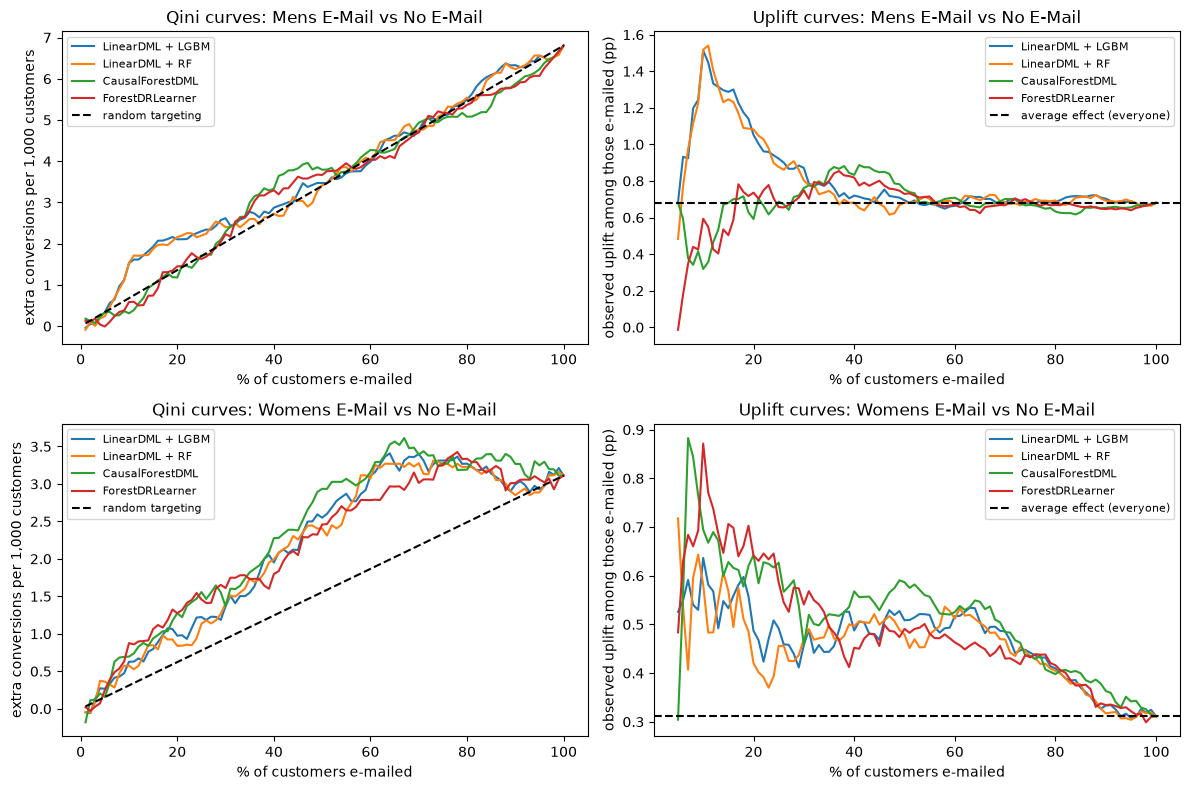

In [30]:
test_holdout, test = test, full      
compare_curves(oof_models, reference="LinearDML + LGBM")
test = test_holdout

In [32]:
def ipw_scores(df, policy):
    share = df[TREATMENT_COL].value_counts(normalize=True)
    match = df[TREATMENT_COL].to_numpy() == np.asarray(policy)
    return df[OUTCOME_COL].to_numpy() * match / df[TREATMENT_COL].map(share).to_numpy()

base = ipw_scores(full, np.full(len(full), "Mens E-Mail"))
policies = {**{n: r["best_segment"] for n, r in oof_models.items()},
            "send nobody": CONTROL, "send everyone Mens": "Mens E-Mail", "send everyone Womens": "Womens E-Mail"}
rows = []
for name, pol in policies.items():
    g = ipw_scores(full, np.full(len(full), pol) if isinstance(pol, str) else pol)
    d = g - base
    rows.append({"policy": name, "conv. rate (%)": g.mean() * 100, "SE": g.std() / np.sqrt(len(g)) * 100,
                 "gain vs everyone-Mens (pp)": d.mean() * 100, "gain SE": d.std() / np.sqrt(len(d)) * 100})
pd.DataFrame(rows).round(3)

,policy,conv. rate (%),SE,gain vs everyone-Mens (pp),gain SE
0,LinearDML + LGBM,1.220,0.075,-0.034,0.045
1,LinearDML + RF,1.229,0.076,-0.024,0.045
2,CausalForestDML,1.215,0.075,-0.038,0.044
3,ForestDRLearner,1.252,0.076,-0.001,0.042
4,send nobody,0.573,0.052,-0.681,0.093
5,send everyone Mens,1.253,0.077,0.000,0.000
6,send everyone Womens,0.884,0.064,-0.369,0.100


## Conclusion

**Average Treatment Effects.** All four causal ML models estimate a positive average effect for both email campaigns compared with no email. The estimated increase in conversion is approximately **0.67 percentage points for Men's E-Mail** and **0.31 percentage points for Women's E-Mail**. These estimates are broadly consistent across models and with the earlier DoWhy analysis. At these effect sizes, emailing 1,000 customers corresponds to approximately 6.7 additional conversions for Men's E-Mail and 3.1 for Women's E-Mail, relative to sending no email, assuming the estimates generalize.

**Treatment Effect Heterogeneity.** The models suggest that some customers may respond more strongly than others. However, the estimated gains from ranking customers by predicted treatment effect are modest and uncertain. The current analysis does not establish that personalized targeting reliably improves outcomes over a simpler campaign policy.

**Model Comparison.** LinearDML with LightGBM and LinearDML with Random Forest produce nearly identical average treatment effect estimates. CausalForestDML and ForestDRLearner provide more flexible estimates of treatment effect heterogeneity. Although some forest-based models have higher estimated Qini scores for Men's E-Mail, uncertainty intervals and paired comparisons do not establish a consistent winner across both email campaigns.

**Predictive Performance.** The nuisance-model evaluation does not demonstrate a meaningful advantage over constant baseline models. This does not invalidate the causal estimates, because treatment was randomized, but it limits the evidence that complex predictive models add value for personalized targeting.

**Policy Evaluation.** The current policy-value comparison estimates a conversion rate of approximately 1.253% for sending everyone Men's E-Mail, compared with 1.220% for LinearDML with LightGBM, 1.229% for LinearDML with Random Forest, 1.215% for CausalForestDML, and 1.252% for ForestDRLearner. The estimated differences are small relative to their standard errors. Therefore, the current analysis does not demonstrate that personalized targeting outperforms sending everyone Men's E-Mail.

**Limitations.** Conversion is rare, at approximately 0.9% in the held-out test set, resulting in relatively few conversion events and noisy subgroup and uplift estimates. Model rankings and customer-level recommendations should therefore be interpreted cautiously. The policy comparison also requires further validation before operational use.

**Recommendation.** Use LinearDML with LightGBM as the reference model for now because its average treatment effect estimates are stable and consistent with the other models. Retain CausalForestDML and ForestDRLearner for further investigation of treatment effect heterogeneity. Use sending everyone Men's E-Mail as the benchmark policy, and validate personalized policies using properly held-out or cross-fitted policy evaluation and, ideally, a prospective randomized experiment.

**Final Decision.** We will continue evaluating the models before selecting a final personalization model. Until stronger evidence is available, LinearDML with LightGBM will remain our reference model, not a proven best-performing model.
